In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
df = pd.read_csv(r"C:\Users\pradn\Downloads\iris.csv")
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


# Display Dataset Shape

In [3]:
print("Number of rows and columns:", df.shape)

Number of rows and columns: (150, 5)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.2 KB


# Statistical Description

In [5]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


# Check Missing Values

In [6]:
print(df.isnull().sum())

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64


In [7]:
print(df.columns)

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='str')


In [8]:
print(df["species"].value_counts())

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


# Separate Features and Target

In [9]:
X = df[["sepal_length", "sepal_width", "petal_length", "petal_width"]]
y = df["species"]

# Encode Target Labels

In [10]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("Species:", le.classes_)
print("Encoded values:", y_encoded)

Species: ['setosa' 'versicolor' 'virginica']
Encoded values: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2]


# Display Encoded Dataset

In [11]:
df["encoded_species"] = y_encoded
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species,encoded_species
0,5.1,3.5,1.4,0.2,setosa,0
1,4.9,3.0,1.4,0.2,setosa,0
2,4.7,3.2,1.3,0.2,setosa,0
3,4.6,3.1,1.5,0.2,setosa,0
4,5.0,3.6,1.4,0.2,setosa,0


# Feature Distribution

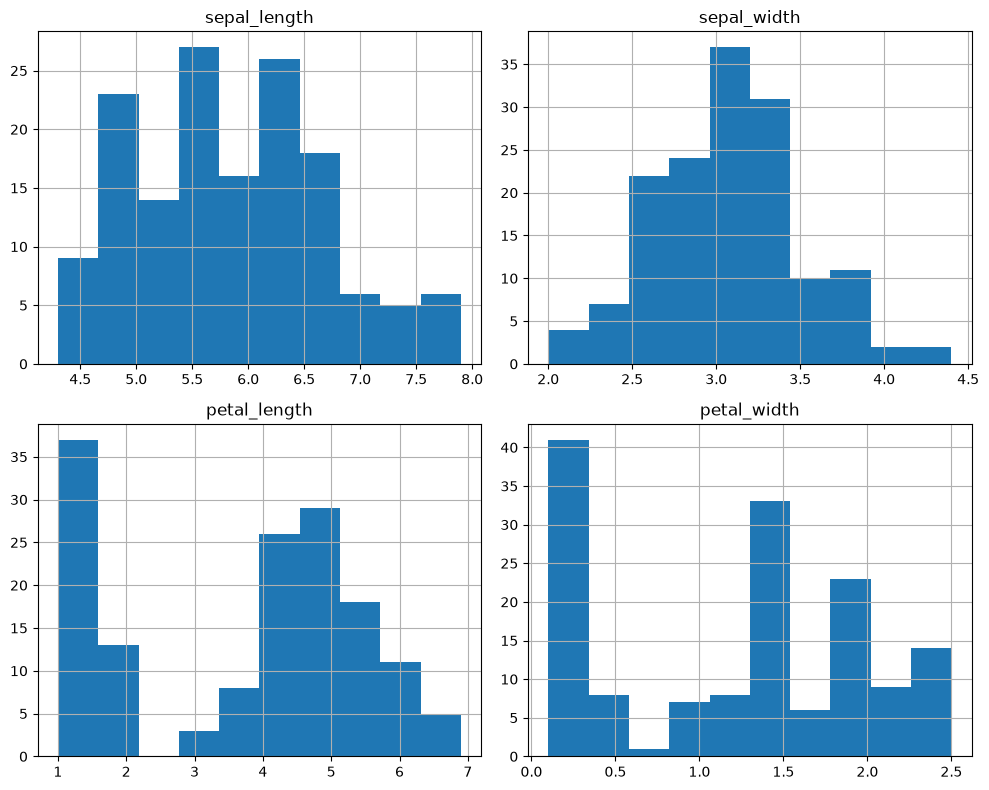

In [12]:
df[["sepal_length", "sepal_width", "petal_length", "petal_width"]].hist(
    figsize=(10, 8)
)
plt.tight_layout()
plt.show()

# Species Distribution

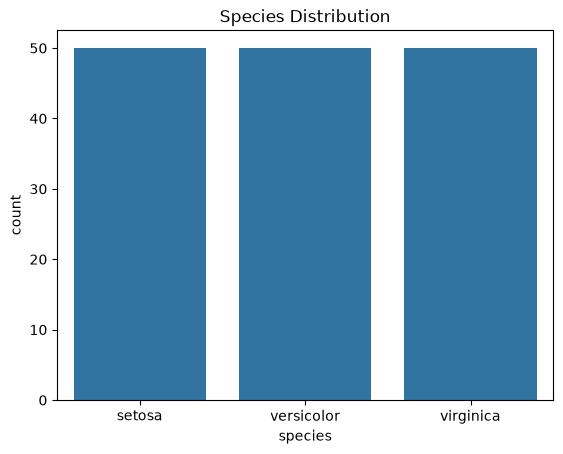

In [13]:
sns.countplot(data=df, x="species")
plt.title("Species Distribution")
plt.show()

# Correlation Matrix

In [14]:
correlation = X.corr()
print(correlation)

              sepal_length  sepal_width  petal_length  petal_width
sepal_length      1.000000    -0.117570      0.871754     0.817941
sepal_width      -0.117570     1.000000     -0.428440    -0.366126
petal_length      0.871754    -0.428440      1.000000     0.962865
petal_width       0.817941    -0.366126      0.962865     1.000000


# Correlation Heatmap

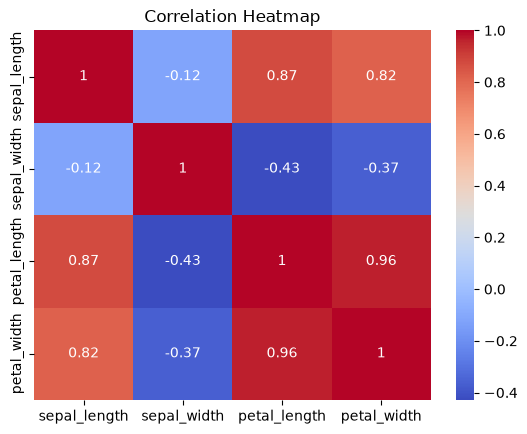

In [15]:
sns.heatmap(correlation, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

# Split Dataset

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (120, 4)
Testing data: (30, 4)


# Feature Scaling

In [17]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Logistic Regression

In [18]:
lr = LogisticRegression(max_iter=200)
lr.fit(X_train_scaled, y_train)

lr_pred = lr.predict(X_test_scaled)

print("Logistic Regression Accuracy:", accuracy_score(y_test, lr_pred))

Logistic Regression Accuracy: 0.9333333333333333


# Decision Tree

In [19]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, dt_pred))

Decision Tree Accuracy: 0.9333333333333333


# Random Forest

In [20]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))

Random Forest Accuracy: 0.9


# Support Vector Machine (SVM)

In [21]:
svm = SVC()
svm.fit(X_train_scaled, y_train)

svm_pred = svm.predict(X_test_scaled)

print("SVM Accuracy:", accuracy_score(y_test, svm_pred))

SVM Accuracy: 0.9666666666666667


# K-Nearest Neighbors (KNN)

In [22]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

knn_pred = knn.predict(X_test_scaled)

print("KNN Accuracy:", accuracy_score(y_test, knn_pred))

KNN Accuracy: 0.9333333333333333


# Naive Bayes

In [23]:
nb = GaussianNB()
nb.fit(X_train, y_train)

nb_pred = nb.predict(X_test)

print("Naive Bayes Accuracy:", accuracy_score(y_test, nb_pred))

Naive Bayes Accuracy: 0.9666666666666667


# Evaluate Models

In [24]:
models = {
    "Logistic Regression": (lr, lr_pred),
    "Decision Tree": (dt, dt_pred),
    "Random Forest": (rf, rf_pred),
    "SVM": (svm, svm_pred),
    "KNN": (knn, knn_pred),
    "Naive Bayes": (nb, nb_pred)
}

for name, (model, pred) in models.items():
    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred, average="weighted", zero_division=0))
    print("Recall:", recall_score(y_test, pred, average="weighted", zero_division=0))
    print("F1 Score:", f1_score(y_test, pred, average="weighted", zero_division=0))


 Logistic Regression
Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1 Score: 0.9333333333333333

 Decision Tree
Accuracy: 0.9333333333333333
Precision: 0.9333333333333333
Recall: 0.9333333333333333
F1 Score: 0.9333333333333333

 Random Forest
Accuracy: 0.9
Precision: 0.9023569023569024
Recall: 0.9
F1 Score: 0.8997493734335839

 SVM
Accuracy: 0.9666666666666667
Precision: 0.9696969696969696
Recall: 0.9666666666666667
F1 Score: 0.9665831244778613

 KNN
Accuracy: 0.9333333333333333
Precision: 0.9444444444444445
Recall: 0.9333333333333333
F1 Score: 0.9326599326599326

 Naive Bayes
Accuracy: 0.9666666666666667
Precision: 0.9696969696969696
Recall: 0.9666666666666667
F1 Score: 0.9665831244778613


# Create Comparison Table

In [25]:
results = []

for name, (model, pred) in models.items():
    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1 Score": f1_score(y_test, pred, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(results)
results_df

,Algorithm,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.933333,0.933333,0.933333,0.933333
1,Decision Tree,0.933333,0.933333,0.933333,0.933333
2,Random Forest,0.900000,0.902357,0.900000,0.899749
3,SVM,0.966667,0.969697,0.966667,0.966583
4,KNN,0.933333,0.944444,0.933333,0.932660
5,Naive Bayes,0.966667,0.969697,0.966667,0.966583


# Compare Accuracy

In [26]:
results_df = results_df.sort_values(by="Accuracy", ascending=False)
print(results_df)

             Algorithm  Accuracy  Precision    Recall  F1 Score
5          Naive Bayes  0.966667   0.969697  0.966667  0.966583
3                  SVM  0.966667   0.969697  0.966667  0.966583
1        Decision Tree  0.933333   0.933333  0.933333  0.933333
0  Logistic Regression  0.933333   0.933333  0.933333  0.933333
4                  KNN  0.933333   0.944444  0.933333  0.932660
2        Random Forest  0.900000   0.902357  0.900000  0.899749


Find Best Classifier

In [27]:
best_model_name = results_df.iloc[0]["Algorithm"]
print("Best Classifier:", best_model_name)
print("Best Accuracy:", results_df.iloc[0]["Accuracy"])

Best Classifier: Naive Bayes
Best Accuracy: 0.9666666666666667


Accuracy Graph

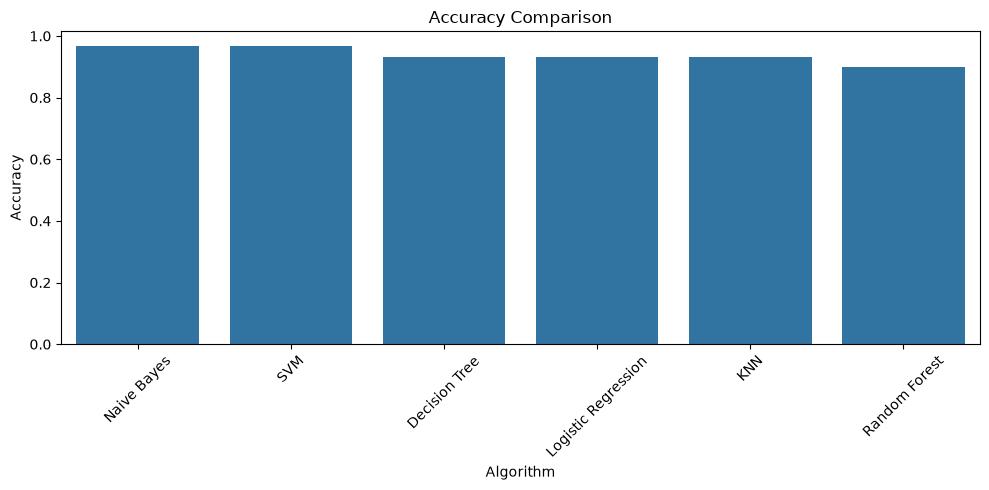

In [28]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Algorithm", y="Accuracy")
plt.xticks(rotation=45)
plt.title("Accuracy Comparison")
plt.tight_layout()
plt.show()

Precision Graph

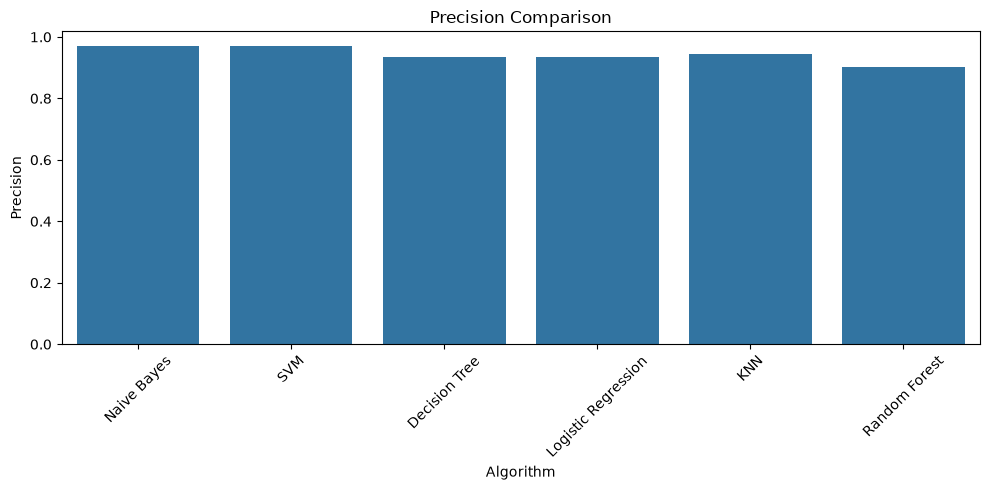

In [29]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Algorithm", y="Precision")
plt.xticks(rotation=45)
plt.title("Precision Comparison")
plt.tight_layout()
plt.show()

Recall Graph

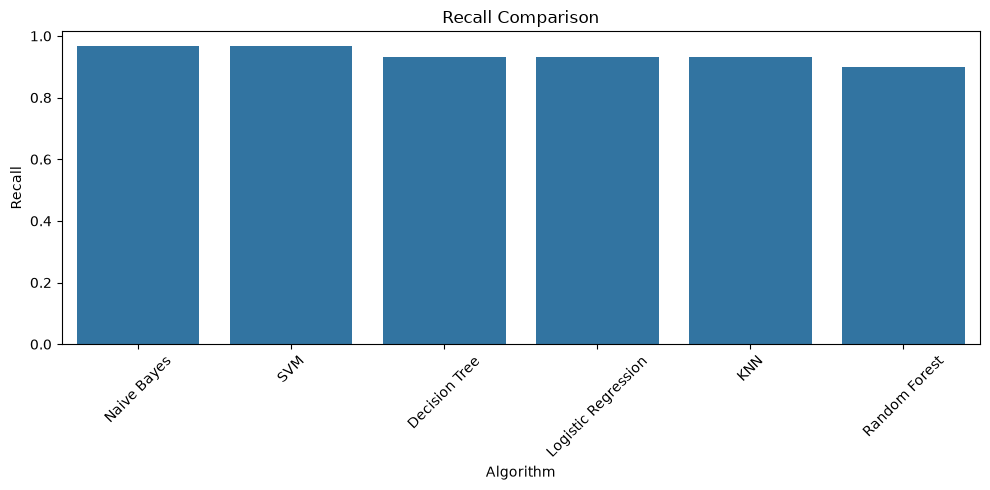

In [30]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Algorithm", y="Recall")
plt.xticks(rotation=45)
plt.title("Recall Comparison")
plt.tight_layout()
plt.show()

F1 Score Graph

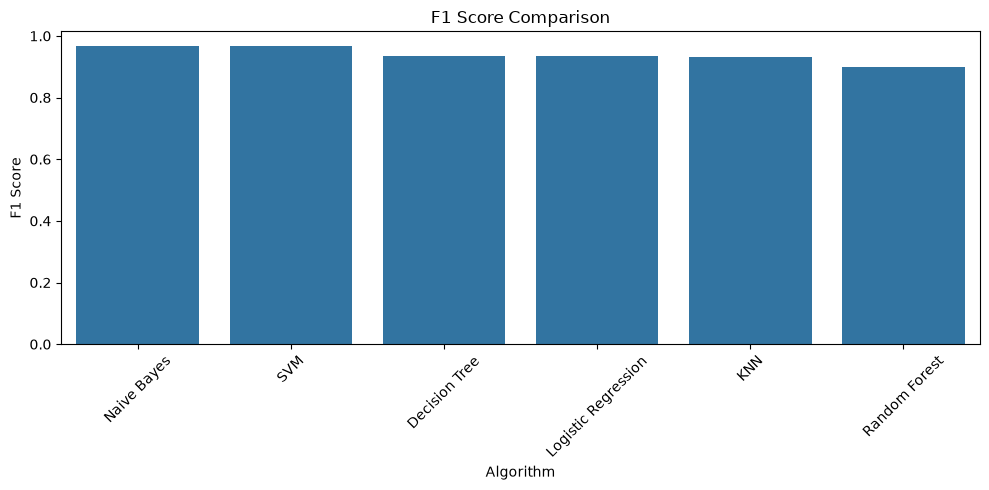

In [31]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Algorithm", y="F1 Score")
plt.xticks(rotation=45)
plt.title("F1 Score Comparison")
plt.tight_layout()
plt.show()

Compare All Metrics

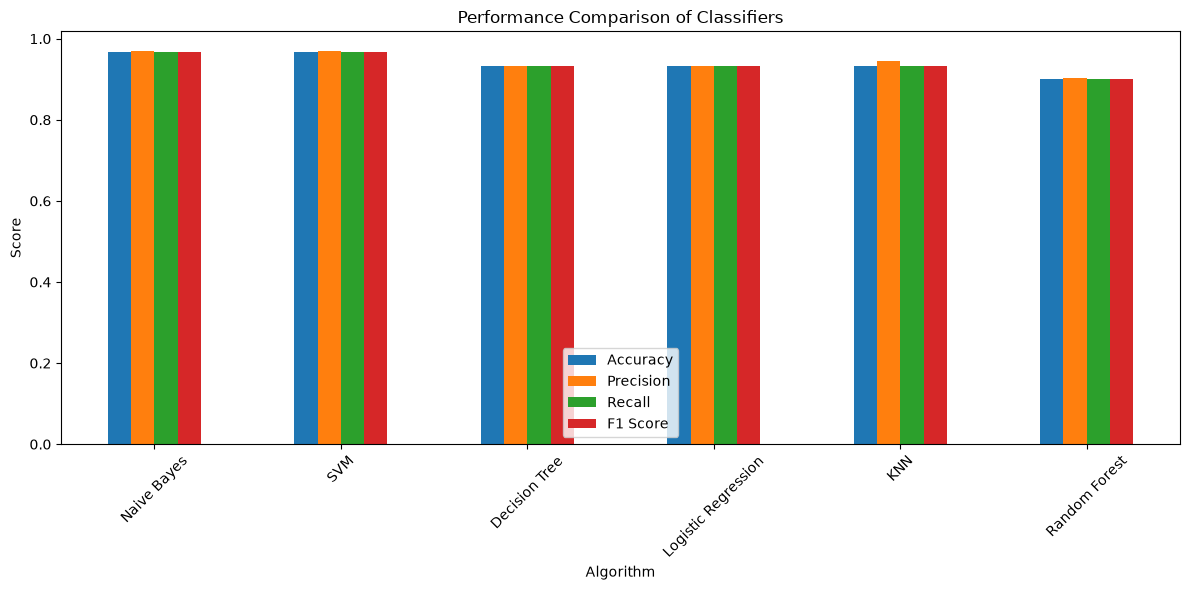

In [32]:
results_df.set_index("Algorithm")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", figsize=(12, 6)
)

plt.title("Performance Comparison of Classifiers")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Confusion Matrix

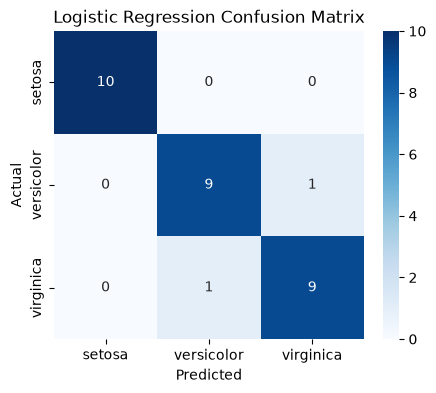

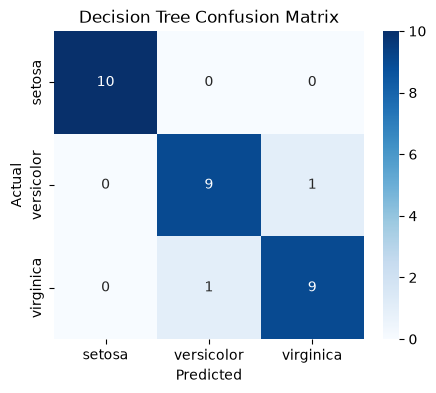

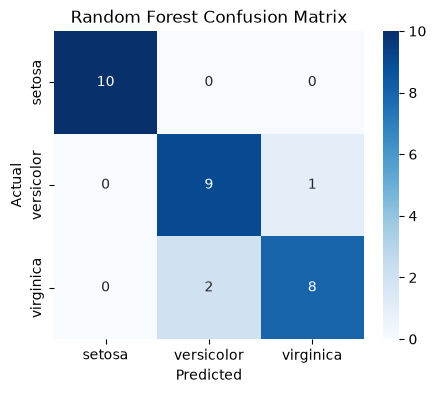

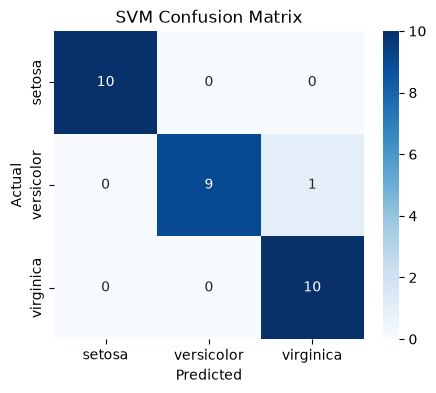

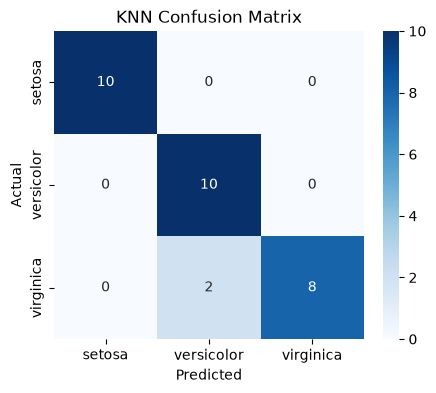

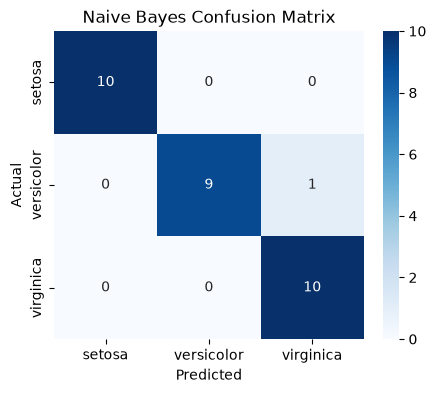

In [33]:
predictions = {
    "Logistic Regression": lr_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "SVM": svm_pred,
    "KNN": knn_pred,
    "Naive Bayes": nb_pred
}

for name, pred in predictions.items():
    cm = confusion_matrix(y_test, pred)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=le.classes_,
        yticklabels=le.classes_
    )

    plt.title(name + " Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

Classification Report

In [34]:
best_model = models[best_model_name][0]
best_prediction = models[best_model_name][1]

print(classification_report(
    y_test, best_prediction, target_names=le.classes_
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



Predict New Flower

In [35]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=["sepal_length", "sepal_width", "petal_length", "petal_width"]
)

if best_model_name in ["Logistic Regression", "SVM", "KNN"]:
    new_flower_input = scaler.transform(new_flower)
else:
    new_flower_input = new_flower

prediction = best_model.predict(new_flower_input)

print("Predicted Species:", le.inverse_transform(prediction)[0])

Predicted Species: setosa
